# Machine Learning Practical · 02
## Shapes, automatic differentiation and optimisation

Exercises for **L2-S36–L2-S60**: parameter counts, activations, forward passes,
loss gradients, gradient descent, mini-batches, projection, momentum and Adam.

[Exercise guide](README.md) · [Worked laboratory](../ML_02_networks_and_optimisation.ipynb)

Python 3.11+; install `../requirements-notebook.txt`, then **Restart Kernel and Run All Cells**.
The starter cells run as supplied; **EDIT** marks the work to complete. Feedback
reports unfinished mathematical tasks without stopping execution. These saved
outputs describe the starting baselines. Allow 75–105 minutes.

**Deliverable:** checked gradients, learning-rate and optimiser comparison plots,
and a record of data, updates, batch sizes and model parameters for each run.

In [1]:
import copy, io, json, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image

SEED = 4
RUN_MODE = "quick"                 # "quick" or "thorough"
assert RUN_MODE in {"quick", "thorough"}
FACTOR = 1 if RUN_MODE == "quick" else 2
START = time.perf_counter()
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__, torch=torch.__version__)
print(json.dumps(versions, indent=2))
print(f"CPU / float64 / seed {SEED} / {RUN_MODE} mode")

palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 110, "legend.frameon": False,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "pink", "blue", "navy"]]),
})

def show_figure(fig):
    """Embed a compact static PNG so GitHub can display the result."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def signal(x):
    return np.sin(np.pi*x)

def sample_data(generator, n, sigma=0.05):
    x = np.sort(generator.uniform(0, 1, n))[:, None]
    y = signal(x) + sigma*generator.normal(size=x.shape)
    return x, y

def make_mlp(width=16, depth=2):
    layers = [nn.Linear(1, width), nn.Tanh()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

{
  "python": "3.13.9",
  "numpy": "2.4.2",
  "matplotlib": "3.10.8",
  "torch": "2.10.0"
}
CPU / float64 / seed 4 / quick mode


## A · Shapes before losses (L2-S36–L2-S44)

1. Predict the tensor shape after every layer of the network below and compute its
   parameter count by hand. Replace `predicted_count` with your answer.
2. Change width and depth; check the count again. Use an activation-free network and
   explain why adding hidden linear layers does not add non-affine expressiveness.
3. Compute the correctly shaped MSE and the broadcast pairwise MSE. Explain why
   both produce scalars although they optimise different objectives.

In [2]:
# EDIT: enter the hand count, then explore other widths/depths and activations.
width, depth = 16, 2
predicted_count = 0                 # starter answer to replace
model = make_mlp(width, depth)
x, y = sample_data(np.random.default_rng(SEED), 32)
X, Y = torch.tensor(x), torch.tensor(y)
activation = X
for layer in model:
    activation = layer(activation)
    print(f"{type(layer).__name__:8s}: {tuple(activation.shape)}")
actual_count = sum(parameter.numel() for parameter in model.parameters())
print("Parameter-count feedback:", "matches" if predicted_count == actual_count else "revise your count")
print("Reference count:", actual_count)
assert activation.shape == Y.shape == (32, 1)
correct_mse = (activation-Y).square().mean()
broadcast_mse = (activation-Y[:, 0]).square().mean()
print(f"Correct MSE {correct_mse.item():.5f}; broadcast MSE {broadcast_mse.item():.5f}")
print("Residual shapes:", tuple((activation-Y).shape), tuple((activation-Y[:, 0]).shape))

Linear  : (32, 16)
Tanh    : (32, 16)
Linear  : (32, 16)
Tanh    : (32, 16)
Linear  : (32, 1)
Parameter-count feedback: revise your count
Reference count: 321
Correct MSE 0.83700; broadcast MSE 0.84639
Residual shapes: (32, 1) (32, 32)


## B · Derive and check an affine gradient (L2-S45, L2-S57–L2-S58)

1. Implement the analytic gradient in `manual_gradient`. Use the parameter order
   `[slope, intercept]` and the mean squared loss (without a factor $1/2$).
2. Compare with autograd and a central finite difference. Sweep the finite-difference
   step from $10^{-2}$ to $10^{-12}$ and explain the error at very small steps.
3. Call `backward()` twice without clearing gradients and inspect what accumulates.
   Use a freshly constructed forward graph for each call.

<details><summary>Hint</summary>

With $A=[x,1]$ and $r=A\beta-y$, the gradient is $2A^Tr/N$.
Use `zero_grad()` before each training update; differentiation accumulates into `.grad`.
</details>

In [3]:
A = np.column_stack([x[:, 0], np.ones(len(x))])
point = np.array([.2, .4])
def objective(beta):
    return np.mean((A @ beta-y[:, 0])**2)
# EDIT: replace this safe, zero-gradient baseline by the analytic expression.
def manual_gradient(beta):
    return np.zeros_like(beta)

beta = torch.tensor(point, requires_grad=True)
loss = (beta[0]*X+beta[1]-Y).square().mean()
loss.backward()
autograd_gradient = beta.grad.detach().numpy().copy()
h = 1e-6
finite_difference = np.array([(objective(point+h*e)-objective(point-h*e))/(2*h) for e in np.eye(2)])
print("Manual: ", manual_gradient(point))
print("Autograd:", autograd_gradient)
print("Finite difference:", finite_difference)
print("Gradient feedback:", "matches" if np.allclose(manual_gradient(point), autograd_gradient, atol=1e-10)
      else "revise the manual gradient")
assert np.allclose(autograd_gradient, finite_difference, atol=1e-8)

Manual:  [0. 0.]
Autograd: [-0.02217399 -0.23735501]
Finite difference: [-0.02217399 -0.23735501]
Gradient feedback: revise the manual gradient


**Your answer:** report your finite-difference error sweep and why it is a diagnostic
rather than an efficient way to train a large network.

## C · Curvature, projection and stochastic updates (L2-S46–L2-S56)

1. Compare steps $0.1/L$, $1/L$ and $2.1/L$, where $L$ is the largest Hessian eigenvalue.
   Explain the observed convergence or divergence using the quadratic eigenvalues.
2. Replace the identity `project` by coordinatewise projection onto $[-r,r]^2$.
   Confirm feasibility after every update and compare the constrained and unconstrained losses.
3. Add mini-batch updates (batch sizes 4 and 16), sampling from a seeded generator.
   Compare equal numbers of gradient updates and record examples processed.
4. Add momentum, or compare PyTorch SGD, RMSProp and Adam on the same initial point.
   State which learning rates were fixed before looking at assessment curves.

<details><summary>Hint</summary>

Use `np.clip` for projection. For a batch of indices `ids`, replace $A,y,N$ in the
gradient by $A_{ids},y_{ids},|ids|$. Keep a full-dataset loss for comparing curves.
</details>

Projection feedback: identity baseline leaves the box
Final coefficients: [-0.58314605  0.98700983]; full-data loss: 0.086546


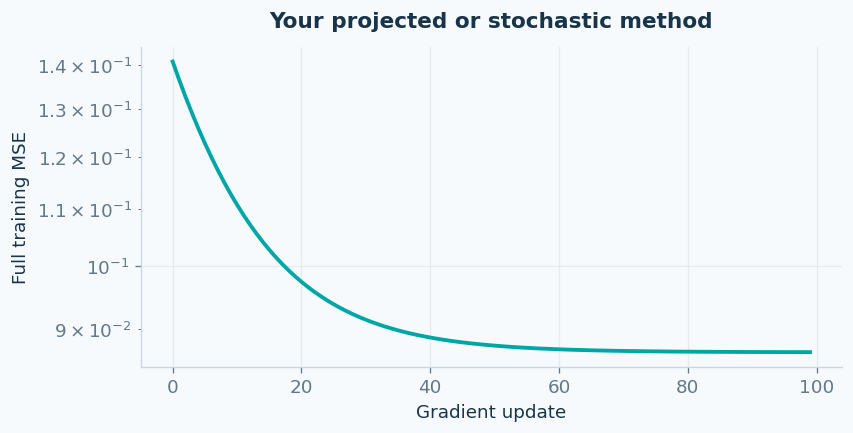

In [4]:
H = 2*A.T @ A/len(A)
L = np.linalg.eigvalsh(H).max()
eta = 1./L
radius = .3
updates = 100
# EDIT: implement box projection; identity is the unprojected baseline.
def project(beta, radius):
    return beta.copy()
def reference_gradient(beta):
    # Supplied here so C runs even before you complete B.
    return 2*A.T @ (A @ beta-y[:, 0])/len(A)
b = np.zeros(2)
loss_history, parameter_history = [], []
for step in range(updates):
    b = project(b-eta*reference_gradient(b), radius)
    loss_history.append(objective(b))
    parameter_history.append(b.copy())
parameter_history = np.asarray(parameter_history)
feasible = np.max(np.abs(parameter_history)) <= radius+1e-12
print("Projection feedback:", "all iterates feasible" if feasible else "identity baseline leaves the box")
print(f"Final coefficients: {b}; full-data loss: {loss_history[-1]:.6f}")
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.semilogy(loss_history)
ax.set(xlabel="Gradient update", ylabel="Full training MSE", title="Your projected or stochastic method")
ax.grid(); show_figure(fig)

## D · Make a small neural experiment reproducible (L2-S51–L2-S60)

The complete training loop below is a baseline for controlled experiments.
Compare two activations and two widths. Keep the data split fixed; reset model and
optimiser state before every run. Increase the update budget and compare with the
small baseline. Record parameters, updates, train MSE and validation MSE.

Implement mini-batching as an extension, and report why an epoch and an update
are different units. Explain why a neural objective can have symmetries, saddle
points or flat directions even when the affine objective was convex.

In [5]:
# EDIT: extend the model/optimiser choices and comparison table.
network_width = 8
training_steps = 100*FACTOR
learning_rate = .01
torch.manual_seed(SEED)
network = make_mlp(network_width, depth=1)
optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)
vx, vy = sample_data(np.random.default_rng(SEED+1), 128)
VX, VY = torch.tensor(vx), torch.tensor(vy)
for step in range(training_steps):
    optimizer.zero_grad(set_to_none=True)
    prediction = network(X)
    assert prediction.shape == Y.shape
    training_loss = (prediction-Y).square().mean()
    training_loss.backward()
    optimizer.step()
network.eval()
with torch.no_grad():
    training_mse = (network(X)-Y).square().mean().item()
    validation_mse = (network(VX)-VY).square().mean().item()
print(dict(seed=SEED, width=network_width, updates=training_steps,
           parameters=sum(p.numel() for p in network.parameters()),
           train_mse=training_mse, validation_mse=validation_mse))

{'seed': 4, 'width': 8, 'updates': 100, 'parameters': 25, 'train_mse': 0.08283060599492495, 'validation_mse': 0.12195168417993825}


**Your experiment record and interpretation:** include all compared settings,
explain one surprising curve, and identify which result depends on initialisation.

**Completion checklist:** correct shapes and parameter count; manual gradient agrees
with autograd; finite-difference sweep interpreted; learning-rate stability explained;
projected iterates feasible; stochastic update accounting recorded; neural comparisons
use a fixed split and reset state.

Continue with [practical 03](ML_Exercises_03_regularisation_and_evaluation.ipynb).